In [19]:
import os
import glob
import re
from collections import defaultdict
 
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [20]:
# zone géographique
lon_min, lon_max = -33, -24
lat_min, lat_max = 29, 37
 
ssh_var = 'ssh_corr'

# données
swot_dir = '/data1/data/obs/level3/SWOT/V-3/'
 
nst_dirs = {
    "SSH + SST": "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH-SST_Azo_swon_1y",
    "SSH seul": "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH_Azo_swon_1y"
}
 
# période pour le calcul annuel
jours = pd.date_range("2024-01-01", "2024-12-31")

In [21]:
# ---------- paramètres ----------
date = pd.Timestamp("2024-04-13")      # jour de la carte NeurOST
d = 15                                # demi-fenêtre utilisée pour ce run
cmems_dir = "/home/nora/projects/NeurOST/input_data/cmems_sla"

# ---------- lecture des traces swon sur la fenêtre ----------
lon_nad = []
lat_nad = []
ecart_nad = []          # écart en jours au jour de la carte

for k in range(-d, d + 1):
    jour = date + pd.Timedelta(days=k)
    # TODO : adapter le motif au nom de tes fichiers swon
    fichiers = sorted(glob.glob(f"{cmems_dir}/swon/dt_global_swon_phy_l3_1hz_{jour:%Y%m%d}_*.nc"))
    for fn in fichiers:
        tr = xr.open_dataset(fn)
        #print(tr)
        lo = (tr.longitude.values + 180) % 360 - 180
        la = tr.latitude.values
        dans_boite = (lo > lon_min) & (lo < lon_max) & (la > lat_min) & (la < lat_max)
        lon_nad.extend(lo[dans_boite])
        lat_nad.extend(la[dans_boite])
        ecart_nad.extend([k] * int(dans_boite.sum()))
        tr.close()

print(len(lon_nad), "points nadir swon dans la boîte")

2847 points nadir swon dans la boîte


1. Exploration d'un jour 

In [22]:
# sélection des fichiers SWOT
 
# 1. fichiers dont le nom contient la date (à vérifier avec un ls)
files = sorted(glob.glob(f"{swot_dir}/*{date:%Y%m%d}T*.nc"))
print(len(files), "fichiers pour", date)
 
# 2. on garde ceux qui passent dans la zone
swot_files = []
for f in files:
    ds = xr.open_dataset(f)
    ds['ssh_corr'] = (ds['ssha_unfiltered']
                    - ds['LongWavelenghtError_cnst_swot_karin']
                    - ds['LongWavelenghtError_lin_swot_karin'])
    lon = ((ds["longitude"] + 180) % 360 - 180).values   # ramené en [-180, 180]
    lat = ds["latitude"].values
    in_box = (lon >= lon_min) & (lon <= lon_max) & (lat >= lat_min) & (lat <= lat_max)
    if in_box.any():
        swot_files.append(f)
        print("OK :", f.split("/")[-1], "-", int(in_box.sum()), "points dans la zone")
    ds.close()
 
print(len(swot_files), "fichiers sélectionnés")

29 fichiers pour 2024-04-13 00:00:00
OK : SWOT_L3_LR_SSH_Expert_013_462_20240413T015150_20240413T024317_v3.0.nc - 10761 points dans la zone
1 fichiers sélectionnés


In [23]:
# ouverture file NeurOST
 
neurost_file = f"/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH_Azo_swon_1y/NeurOST_SSH_Azo_swon_1y_L250km_20240102_20261118.nc"
nst = xr.open_dataset(neurost_file).isel(time=0)

In [ ]:
# PLOT
 
fig, axes = plt.subplots(1, 4, figsize=(15, 5), squeeze=False)
ds = xr.open_dataset(swot_files[0])

ds['ssh_corr'] = (ds['ssha_unfiltered']
                - ds['LongWavelenghtError_cnst_swot_karin']
                - ds['LongWavelenghtError_lin_swot_karin'])

lon = (ds.longitude + 180) % 360 - 180
lat = ds.latitude
box = (lon > lon_min) & (lon < lon_max) & (lat > lat_min) & (lat < lat_max)

swot = ds['ssh_corr'].where(box)
# NeurOST est en 0-360
neurost = nst.sla.interp(longitude=(ds.longitude % 360).where(box), latitude=lat.where(box))
diff = neurost - swot
rmse = np.sqrt(diff**2)
print (diff.mean().values, diff.std().values)
rmse_mean = float(np.sqrt((diff**2).mean()))
print(f.split("/")[-1], f"rmse={rmse_mean:.3f}")
 
v_ssh = float(np.nanpercentile(np.abs(swot), 98))
v_diff = float(np.nanpercentile(np.abs(diff), 98))
#v_diff = 0.23312918666477533
#v_rmse = float(np.nanpercentile(np.abs(rmse), 98))
v_rmse = 0.23312918666477533


    #for ax, d, title, v in zip(row, [swot, neurost, diff],
     #                       ["SWOT", "NeurOST interp sur SWOT", "NeurOST - SWOT"],
     #                       [v_ssh, v_ssh, v_diff]):


cmaps = ["RdBu_r", "RdBu_r", "RdBu_r", "Reds"]
vmins = [-v_ssh, -v_ssh, -v_diff, 0]
vmaxs = [v_ssh, v_ssh, v_diff, v_rmse]
titles = ["SWOT", "NeurOST interp sur SWOT", "NeurOST - SWOT", "RMSE"]

for i, (ax, dd, title, cmap, vmin, vmax) in enumerate(zip(axes[0], [swot, neurost, diff, rmse],
                                                          titles, cmaps, vmins, vmaxs)):
    im = ax.pcolormesh(lon, lat, dd, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.7)

    if i == 0:      # premier panneau : on ajoute les traces nadirz
        sc = ax.scatter(lon_nad, lat_nad, 
                        color='black',alpha=0.3,
                        vmin=-max(d, 1), vmax=max(d, 1), s=0.3)
        #fig.colorbar(sc, ax=ax, shrink=0.7, label="jours depuis la carte")

fig.suptitle(f'jours de nadir SWOT vus avant/après : {d} - rmse_mean={rmse_mean:.3f}')
plt.tight_layout()

In [24]:
def lire_nadir_swon(date, d):
    # renvoie lon, lat des points swon dans la boîte, de J-d à J+d
    lon_nad = []
    lat_nad = []
    for k in range(-d, d + 1):
        jour = date + pd.Timedelta(days=k)
        fichiers = sorted(glob.glob(f"{cmems_dir}/swon/dt_global_swon_phy_l3_1hz_{jour:%Y%m%d}_*.nc"))
        if not fichiers:
            continue
        tr = xr.open_dataset(fichiers[-1])
        lo = (tr.longitude.values + 180) % 360 - 180
        la = tr.latitude.values
        ok = (lo > lon_min) & (lo < lon_max) & (la > lat_min) & (la < lat_max)
        lon_nad.extend(lo[ok])
        lat_nad.extend(la[ok])
        tr.close()
    return lon_nad, lat_nad

v_ssh = float(np.nanpercentile(np.abs(swot), 98))
v_diff = 0.233          # même échelle pour les trois runs, pour pouvoir comparer

for d in range(16):     # demi-fenêtre de 0 à 15 jours
    fichiers_nst = sorted(glob.glob(f"/home/nora/projects/NeurOST/predictions/merged_products/"
                                    f"NeurOST_SSH_GS_swon_{d}j_1month/*_{date:%Y%m%d}_*.nc"))
    nst = xr.open_dataset(fichiers_nst[-1]).isel(time=0)

    neurost = nst.sla.interp(longitude=(ds.longitude % 360).where(box), latitude=lat.where(box))
    diff = neurost - swot
    rmse = np.sqrt(diff**2)
    rmse_mean = float(np.sqrt((diff**2).mean()))
    print(d, "jours :", float(diff.mean()), float(diff.std()), f"rmse={rmse_mean:.3f}")

    lon_nad, lat_nad = lire_nadir_swon(date, d)

    fig, axes = plt.subplots(1, 4, figsize=(15, 5))      # une nouvelle figure à chaque tour

    cmaps = ["RdBu_r", "RdBu_r", "RdBu_r", "Reds"]
    vmins = [-v_ssh, -v_ssh, -v_diff, 0]
    vmaxs = [v_ssh, v_ssh, v_diff, v_diff]
    titles = ["SWOT", "NeurOST interp sur SWOT", "NeurOST − SWOT", "RMSE"]

    for i, (ax, dd, title, cmap, vmin, vmax) in enumerate(zip(axes, [swot, neurost, diff, rmse],
                                                              titles, cmaps, vmins, vmaxs)):
        im = ax.pcolormesh(lon, lat, dd, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_xlim(lon_min, lon_max)
        ax.set_ylim(lat_min, lat_max)
        ax.set_title(title)
        fig.colorbar(im, ax=ax, shrink=0.7)
        if i == 0:
            ax.scatter(lon_nad, lat_nad, color='black', alpha=0.3, s=0.3)

    fig.suptitle(f"NeurOST SSH seul, swon ±{d} j — {date:%d/%m/%Y} — RMSE = {rmse_mean:.3f} m")
    fig.tight_layout()
    #fig.savefig(f"figures/carte_GS_swon_{d}j_{date:%Y%m%d}.png", dpi=150)
    plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'where'

20240401 SSH seul: 0.0702 | SSH + SST: 0.0485
20240402 SSH seul: 0.0897 | SSH + SST: 0.0654
20240403 SSH seul: 0.1197 | SSH + SST: 0.0635
20240404 SSH seul: 0.1063 | SSH + SST: 0.0748
20240405 SSH seul: 0.0869 | SSH + SST: 0.0574
20240406 SSH seul: NaN | SSH + SST: NaN
20240407 SSH seul: NaN | SSH + SST: NaN
20240408 SSH seul: NaN | SSH + SST: NaN
20240409 SSH seul: NaN | SSH + SST: NaN
20240410 SSH seul: 0.0640 | SSH + SST: 0.0546
20240411 SSH seul: 0.0858 | SSH + SST: 0.0524
20240412 SSH seul: 0.0783 | SSH + SST: 0.0598
20240413 SSH seul: 0.1325 | SSH + SST: 0.0778
20240414 SSH seul: 0.0843 | SSH + SST: 0.0490
20240415 SSH seul: 0.0835 | SSH + SST: 0.0479
20240416 SSH seul: NaN | SSH + SST: NaN
20240417 SSH seul: NaN | SSH + SST: NaN
20240418 SSH seul: NaN | SSH + SST: NaN
20240419 SSH seul: NaN | SSH + SST: NaN
20240420 SSH seul: NaN | SSH + SST: NaN
20240421 SSH seul: 0.0670 | SSH + SST: 0.0520
20240422 SSH seul: 0.0671 | SSH + SST: 0.0495
20240423 SSH seul: 0.0686 | SSH + SST: 0.0

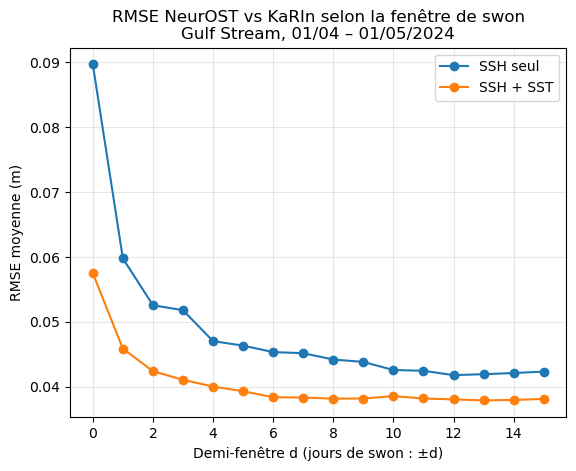

In [29]:
# ⚠️ les runs _1month sont sur le Gulf Stream : il faut la boîte GS
lon_min, lon_max = -65, -55
lat_min, lat_max = 34, 42

jours_avril = pd.date_range("2024-04-01", "2024-05-01")

nst_dirs_fenetre = {
    "SSH seul":  "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH_GS_swon_{d}j_1month",
    "SSH + SST": "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH-SST_GS_swon_{d}j_1month",
}

rmse_par_d = {"SSH seul": [], "SSH + SST": []}

for d in range(16):
    # les deux dossiers pour ce d
    dossiers = {config: chemin.format(d=d) for config, chemin in nst_dirs_fenetre.items()}

    # RMSE de chaque jour d'avril, pour les deux configs
    res = calcul_rmse(dossiers, swot_dir, jours_avril)

    # moyenne sur le mois (les jours sans SWOT dans la boîte = NaN, ignorés)
    for config in rmse_par_d:
        rmse_par_d[config].append(np.nanmean(res[config]))

    print(f"d = {d} :", {c: round(rmse_par_d[c][-1], 4) for c in rmse_par_d})

# --- figure ---
for config in rmse_par_d:
    plt.plot(range(16), rmse_par_d[config], marker='o', label=config)

plt.xlabel("Demi-fenêtre d (jours de swon : ±d)")
plt.ylabel("RMSE moyenne (m)")
plt.grid(alpha=0.3)
plt.title("RMSE NeurOST vs KaRIn selon la fenêtre de swon\nGulf Stream, 01/04 – 01/05/2024")
plt.legend()
plt.show()

2. RMSE journalier sur l'année

In [ ]:
# --------------------------------------------------
# Indexation des fichiers
# --------------------------------------------------
 
def indexer_nst(dossier):
    fichiers = defaultdict(list)
 
    for f in glob.glob(os.path.join(dossier, "*.nc")):
        match = re.search(r"_(\d{8})_", os.path.basename(f))
        if match:
            fichiers[match.group(1)].append(f)
 
    return fichiers
 
 
def indexer_swot(dossier):
    fichiers = defaultdict(list)
 
    for f in glob.glob(os.path.join(dossier, "*.nc")):
        match = re.search(r"_(\d{8})T", os.path.basename(f))
        if match:
            fichiers[match.group(1)].append(f)
 
    return fichiers

In [27]:
# --------------------------------------------------
# Calcul des RMSE
# --------------------------------------------------
 
def calcul_rmse(nst_dirs, swot_dir, jours):
 
    nst_index = {
        nom: indexer_nst(dossier)
        for nom, dossier in nst_dirs.items()
    }
 
    swot_index = indexer_swot(swot_dir)
 
    rmse = {nom: [] for nom in nst_dirs}
 
    for jour in jours:
 
        d = jour.strftime("%Y%m%d")
 
        # Réinitialisation quotidienne
        somme_jour = {nom: 0.0 for nom in nst_dirs}
        compte_jour = {nom: 0 for nom in nst_dirs}
 
        # Vérifier la présence des cartes NeurOST
        cartes = {}
 
        for nom in nst_dirs:
            fichiers = sorted(nst_index[nom][d])
 
            if fichiers:
                cartes[nom] = xr.open_dataset(fichiers[-1])
 
        # Vérifier la présence des fichiers SWOT
        fichiers_swot = sorted(swot_index[d])
 
        if not cartes or not fichiers_swot:
            for nom in nst_dirs:
                rmse[nom].append(np.nan)
 
            for ds in cartes.values():
                ds.close()
 
            continue
 
        # Charger les cartes NeurOST une seule fois
        cartes_chargees = {}
 
        for nom, ds in cartes.items():
            cartes_chargees[nom] = ds.isel(time=0).load()
 
        # Parcours des fichiers SWOT du jour
        for f in fichiers_swot:
 
            with xr.open_dataset(f) as ds:

                ds['ssh_corr'] = (ds['ssha_unfiltered']
                                    - ds['LongWavelenghtError_cnst_swot_karin']
                                    - ds['LongWavelenghtError_lin_swot_karin'])
 
                lon = ds.longitude.values
                lat = ds.latitude.values
                swot = ds['ssh_corr'].values
 
                # Masque spatial
                lon_norm = (lon + 180) % 360 - 180
 
                mask = (
                    (lon_norm > lon_min) &
                    (lon_norm < lon_max) &
                    (lat > lat_min) &
                    (lat < lat_max) &
                    np.isfinite(swot)
                )
 
                if not mask.any():
                    continue
 
                # Coordonnées des seuls points SWOT utiles
                lon_pts = (lon[mask] % 360)
                lat_pts = lat[mask]
                swot_pts = swot[mask]
 
                lon_interp = xr.DataArray(lon_pts, dims="points")
                lat_interp = xr.DataArray(lat_pts, dims="points")
 
                # Comparaison avec chaque configuration NeurOST
                for nom, nst in cartes_chargees.items():
 
                    nn = nst.sla.interp(
                        longitude=lon_interp,
                        latitude=lat_interp
                    ).values
 
                    diff = nn - swot_pts
 
                    valid = np.isfinite(diff)
 
                    somme_jour[nom] += np.sum(diff[valid]**2)
                    compte_jour[nom] += valid.sum()
 
        # Fermeture des datasets
        for ds in cartes.values():
            ds.close()
 
        # RMSE journalier
        for nom in nst_dirs:
 
            n = compte_jour[nom]
 
            valeur = (
                np.sqrt(somme_jour[nom] / n)
                if n > 0 else np.nan
            )
 
            rmse[nom].append(valeur)
 
        print(
            d,
            " | ".join(
                f"{nom}: {rmse[nom][-1]:.4f}"
                if np.isfinite(rmse[nom][-1])
                else f"{nom}: NaN"
                for nom in nst_dirs
            )
        )
 
    return {nom: np.array(val) for nom, val in rmse.items()}

In [ ]:

# --------------------------------------------------
# Exécution + sauvegarde
# --------------------------------------------------
nst_dirs = {
    "SSH + SST": "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH-SST_Azo_swon_1y",
    "SSH seul":  "/home/nora/projects/NeurOST/predictions/merged_products/NeurOST_SSH_Azo_swon_1y",
}

resultats = calcul_rmse(nst_dirs, swot_dir)

df = pd.DataFrame({
    "date": jours,
    "RMSE_SSH_SST": resultats["SSH + SST"],
    "RMSE_SSH": resultats["SSH seul"]
})
df.to_csv("/home/nora/projects/NeurOST/my_work/files/RMSE_NeurOST_Azo_swon_2024.csv", index=False)

3. Visualisation

In [ ]:
# relecture du CSV (parse_dates pour que l'axe x soit reconnu comme des dates)
 
df_azo = pd.read_csv("/home/nora/projects/NeurOST/my_work/files/RMSE_NeurOST_Azo_swon_2024.csv", parse_dates=["date"])
 
rmse_sst_mean_azo = df_azo["RMSE_SSH_SST"].mean()   # les NaN sont ignorés
rmse_ssh_mean_azo = df_azo["RMSE_SSH"].mean()

#df_gs = pd.read_csv("/home/nora/projects/NeurOST/my_work/files/RMSE_NeurOST_GS_swon_2024.csv", parse_dates=["date"])

#rmse_sst_mean_gs = df_gs["RMSE_SSH_SST"].mean()   # les NaN sont ignorés
#rmse_ssh_mean_gs = df_gs["RMSE_SSH"].mean()

In [ ]:
fig, ax = plt.subplots(figsize=(15, 5))
 
ax.plot(df_azo["date"], df_azo["RMSE_SSH"], "o-", markersize=2, color='tab:blue', label="SSH seul", alpha=0.7)
ax.plot(df_azo["date"], df_azo["RMSE_SSH_SST"], "o-", markersize=2, color='tab:orange', label="SSH + SST", alpha=0.7)
ax.axhline(rmse_ssh_mean_azo, color='tab:blue', linestyle='--', label=f'Moyenne SSH seul ({rmse_ssh_mean_azo:.3f} m)')
ax.axhline(rmse_sst_mean_azo, color='tab:orange', linestyle='--', label=f'Moyenne SSH + SST ({rmse_sst_mean_azo:.3f} m)')


#ax.set_ylim(df_azo[["RMSE_SSH_SST", "RMSE_SSH"]].min().min() - 0.01, df_azo[["RMSE_SSH_SST", "RMSE_SSH"]].max().max() + 0.01)
 
ax.set_ylabel("RMSE NeurOST - SWOT (m)")
ax.set_title("Azores – 2024")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
#plt.savefig("rmse_2024.png", dpi=150)
plt.show()